# Week 3: OLS Demand Model

In [2]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load competition data and show some stats

In [3]:
df_comp_details = pd.read_csv('../duopoly_competition_details1.csv')
df_comp_details.fillna(0, inplace=True)

df_comp_details['revenue'] = df_comp_details['price'] * df_comp_details['demand']

df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,revenue
0,3HmCSH,1,1,SaffronDolphin,56.1,66.4,0,True,0.005,0.0,0.0
1,3HmCSH,1,2,SaffronDolphin,66.4,66.4,0,True,0.006,0.0,0.0
2,3HmCSH,1,3,SaffronDolphin,66.4,66.4,0,True,0.007,0.0,0.0


In [4]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

In [5]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev.head(3)

,unique_selling_season_key,revenue
0,3HmCSH_1,363.7
1,3HmCSH_10,1266.4
2,3HmCSH_100,399.7


# Let us build our own demand model based on the competition data.

## => f(price, competitor_price) = demand

## idea:
- split selling_season into sub-intervals where we assume a constant demand model
    - e.g. selling period [1,20] assumed to have almost constant demand
- estimate the demand model per competition
- train on first 50 selling_seasons and evaluate on the last 50

3UDGYU


<Axes: >

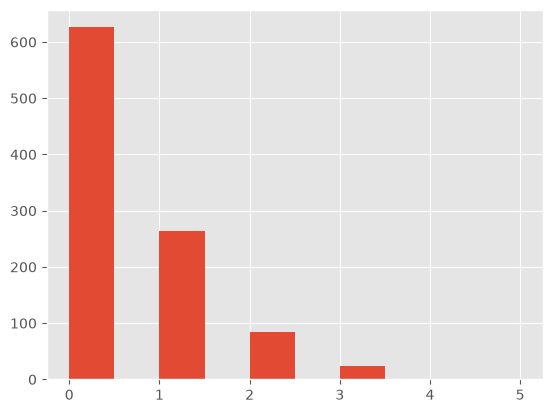

In [6]:
comp = df_comp_details.competition_id.unique()[1]
print(comp)

# filter on first competion_id
df = df_comp_details[df_comp_details.competition_id==comp ]

# concentrate on selling period in [1,20]
df = df[df.selling_period <= 20 ]

df_train = df[df.selling_season<=50]
df_test = df[df.selling_season>50]

df_train.demand.hist()

<Axes: >

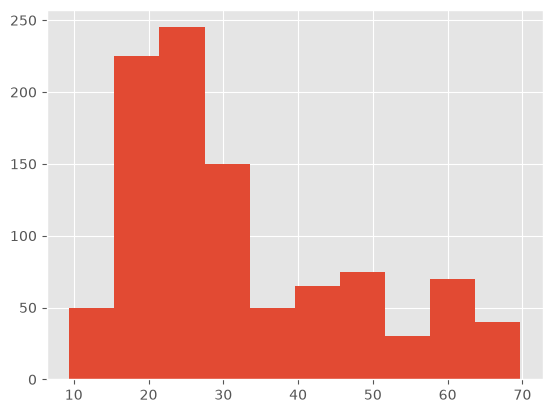

In [7]:
# df_train.head(35)
# df_train.demand.hist()
df_train.price.hist()

<Axes: >

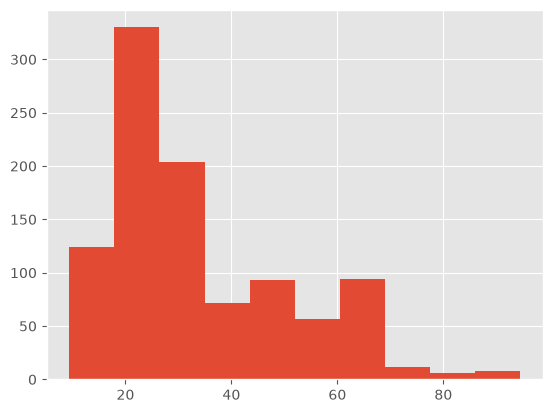

In [8]:
df_train.price_competitor.hist()

## (a) fit OLS model

In [9]:
import statsmodels.api as sm
# https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html

y = df_train.demand
X = df_train[['price', 'price_competitor']] 
X['intercept'] = 1


mod = sm.OLS(y, X)
# mod = sm.regression.quantile_regression.QuantReg(y,X)

res = mod.fit()

print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                 demand   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     105.2
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           3.66e-42
Time:                        18:09:37   Log-Likelihood:                -1062.7
No. Observations:                1000   AIC:                             2131.
Df Residuals:                     997   BIC:                             2146.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
price               -0.0363      0.003  

## (b) predict demand based on function for
- own price = 30
- competitor price = 50

In [10]:
mod.predict(res.params, [30,50,1])

np.float64(0.8582656278057412)

## (c) simulate demand, our prices in [1,100] and competitor_price = 50

In [11]:

def est_demand(price, comp_price, para = res.params):
    demand = mod.predict(para, [price, comp_price, 1])
    demand = max(0,demand)
    return demand

df_sim = pd.DataFrame(columns = ['price','demand','rev'])
for p in np.arange(1,100,1):
    demand = est_demand(price=p, comp_price=90)
    rev = p * demand
    df_sim.loc[len(df_sim)] = [p,demand,rev]

    
df_sim.head()

,price,demand,rev
0,1.0,2.599371,2.599371
1,2.0,2.563051,5.126102
2,3.0,2.526730,7.580191
3,4.0,2.490410,9.961641
4,5.0,2.454090,12.270449


#### plot demand and revenue curve

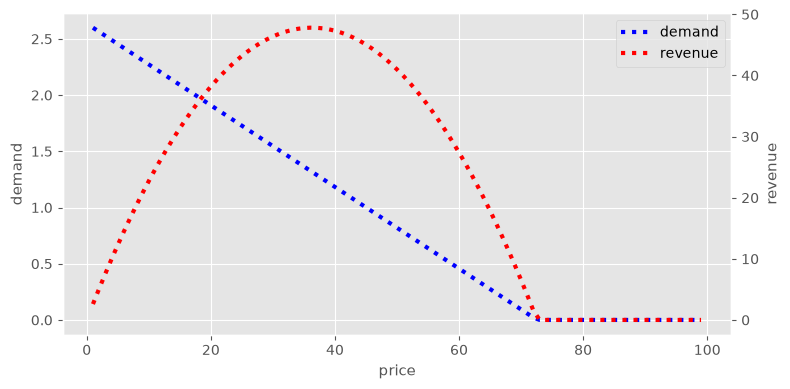

In [12]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df_sim['price'], df_sim['demand'], color='b', 
        linestyle='dotted', linewidth=3, label='demand')

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(df_sim['price'], df_sim['rev'], color='r', 
        linestyle='dotted', linewidth=3, label='revenue')

ax_2.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="both", labelsize=10)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)
ax_2.set_ylabel("revenue" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

## (d) compute estimated demand in computation details

In [13]:
df_eval = df_test[['unique_selling_season_key','selling_season','selling_period','price_competitor', 'price', 'demand']]

df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand
15000,3UDGYU_51,51,1,48.6,55.7,0
15001,3UDGYU_51,51,2,55.7,55.7,0
15002,3UDGYU_51,51,3,55.7,55.7,0
15003,3UDGYU_51,51,4,55.7,55.7,0
15004,3UDGYU_51,51,5,55.7,55.7,0


In [14]:
# estimate demand
# estimate demand
df_eval['est_demand'] = df_eval.apply(lambda r:
            est_demand(price=r.price, comp_price=r.price_competitor),
            axis=1)

# compute error metrics
df_eval['est_error'] = df_eval['est_demand'] - df_eval['demand']
df_eval['abs_est_error'] = df_eval['est_error'].abs()


df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand,est_demand,est_error,abs_est_error
15000,3UDGYU_51,51,1,48.6,55.7,0,0.000000,0.000000,0.000000
15001,3UDGYU_51,51,2,55.7,55.7,0,0.022847,0.022847,0.022847
15002,3UDGYU_51,51,3,55.7,55.7,0,0.022847,0.022847,0.022847
15003,3UDGYU_51,51,4,55.7,55.7,0,0.022847,0.022847,0.022847
15004,3UDGYU_51,51,5,55.7,55.7,0,0.022847,0.022847,0.022847


In [15]:
df_eval[['demand', 'est_demand', 'est_error', 'abs_est_error']].describe()

,demand,est_demand,est_error,abs_est_error
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.499000,0.508571,0.009571,0.531667
std,0.789064,0.281578,0.723361,0.490296
min,0.000000,0.000000,-3.466518,0.000000
25%,0.000000,0.315793,-0.305868,0.221746
50%,0.000000,0.556432,0.137597,0.449333
75%,1.000000,0.699869,0.554520,0.675874
max,4.000000,1.057409,1.046025,3.466518


### plot the actual demand vs. estimated demand for one test selling season

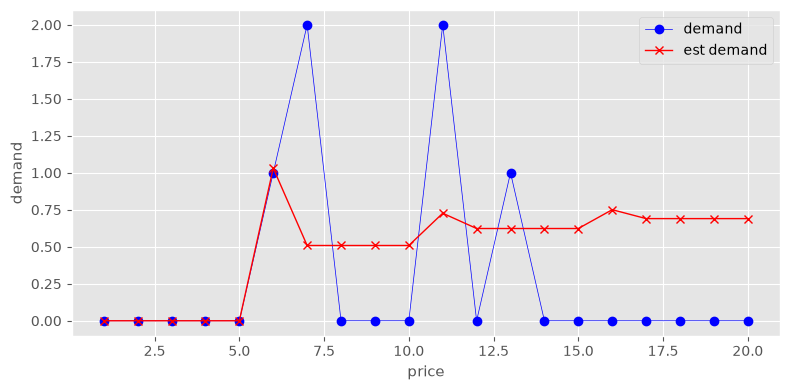

In [16]:
dfe = df_eval[df_eval.selling_season==60]

fig, ax = plt.subplots(figsize=(8,4))

ax.plot(dfe['selling_period'], dfe['demand'], color='b', 
        linestyle='-', marker='o', linewidth=0.5, markersize=6, label='demand')

ax.plot(dfe['selling_period'], dfe['est_demand'], color='r', 
        linestyle='-', marker='x', linewidth=1, markersize=6, label='est demand')

ax.legend( loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

# next tasks:
## (1) estimate five demand models covering the 100 period selling_season
## (2) estimate demand models for every simulation_id 
## (3) implement the demand model in your own simulation (last week simulation notebook)
## (4) implement the demand model estimation & next price optimization in your pricing algorithm

In [17]:
# --- TÂCHES (1) & (2) : 5 modèles sur les 100 périodes pour chaque compétition ---
ols_models = {}

for comp in df_comp_details.competition_id.unique():
    print("=========================================")
    print("Compétition :", comp)
    ols_models[comp] = {}
    
    # Boucle de 20 en 20 jusqu'à 100 (20, 40, 60, 80, 100)
    for p_max in range(20, 101, 20):
        p_min = p_max - 19  # 1, 21, 41, 61, 81
        
        # Copié-collé du code du prof
        df = df_comp_details[df_comp_details.competition_id == comp]
        df = df[(df.selling_period >= p_min) & (df.selling_period <= p_max)]
        
        df_train = df[df.selling_season <= 50]
        
        y = df_train.demand
        X = df_train[['price', 'price_competitor']] 
        X['intercept'] = 1
        
        mod = sm.OLS(y, X)
        res = mod.fit()
        
        # On garde les paramètres en mémoire pour la période p_max (20, 40, 60, 80 ou 100)
        ols_models[comp][p_max] = res.params.to_dict()
        print(f"Période [{p_min}, {p_max}] -> price: {res.params['price']:.4f}, comp: {res.params['price_competitor']:.4f}, intercept: {res.params['intercept']:.4f}")

# On sauvegarde les 5 modèles de la dernière compétition dans un fichier pickle à la racine
with open('../ols_demand_models.pkl', 'wb') as f:
    pickle.dump(ols_models[comp], f)

print("\nFichier '../ols_demand_models.pkl' bien créé !")

Compétition : 3HmCSH
Période [1, 20] -> price: -0.0299, comp: 0.0115, intercept: 0.9819
Période [21, 40] -> price: -0.0604, comp: 0.0467, intercept: 0.8657
Période [41, 60] -> price: -0.1449, comp: 0.1353, intercept: 0.9659
Période [61, 80] -> price: -0.0971, comp: 0.0907, intercept: 1.0316
Période [81, 100] -> price: -0.0794, comp: 0.0588, intercept: 1.1548
Compétition : 3UDGYU
Période [1, 20] -> price: -0.0363, comp: 0.0172, intercept: 1.0881
Période [21, 40] -> price: -0.0841, comp: 0.0654, intercept: 1.0552
Période [41, 60] -> price: -0.1829, comp: 0.1790, intercept: 0.9180
Période [61, 80] -> price: -0.1385, comp: 0.1338, intercept: 1.0566
Période [81, 100] -> price: -0.2059, comp: 0.1915, intercept: 1.1503
Compétition : bh2y6f
Période [1, 20] -> price: -0.0247, comp: 0.0122, intercept: 1.1333
Période [21, 40] -> price: -0.0271, comp: 0.0148, intercept: 1.1431
Période [41, 60] -> price: -0.0530, comp: 0.0435, intercept: 1.1546
Période [61, 80] -> price: -0.0377, comp: 0.0352, inte